# 01 · Data Cleaning and Exploratory Analysis

**Project:** AI Retail Analytics Copilot
**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): ~99,000 real, anonymised orders (2016–2018) across 9 linked tables

**Goal of this notebook:** understand the data, find and fix quality problems, discover what drives late deliveries and bad reviews, and produce one clean, order-level **master table** that every later step (ML models, forecasting, the AI assistant) is built on.

### Contents
1. Setup and loading
2. Orders and customers: first look
3. Missing and impossible values
4. Cleaning the orders table
5. Delivery performance
6. Outliers and a batch-update problem
7. Data coverage: the reliable time window
8. Reviews: do late deliveries cause bad reviews?
9. Order items and products
10. Other causes of bad reviews
11. Payments
12. Geography: states, distance and the Feb–Mar 2018 crisis
13. Building the master table
14. Cleaning decisions and key insights

## 1. Setup and loading

The notebook runs in Google Colab (data in Google Drive) or locally (data in a `data/` folder next to `notebooks/`). The raw CSV files are not stored in this repository; download them from Kaggle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (12, 4)

# Data location: Google Drive in Colab, otherwise a local data/ folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/Olist/'
except ImportError:
    DATA_PATH = '../data/'

Mounted at /content/drive


In [2]:
files = {
    'orders': 'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
}

raw = {name: pd.read_csv(DATA_PATH + file_name) for name, file_name in files.items()}

# Size of every table
pd.DataFrame({'rows': {name: len(table) for name, table in raw.items()},
              'columns': {name: table.shape[1] for name, table in raw.items()}})

,rows,columns
orders,99441,8
order_items,112650,7
customers,99441,5
payments,103886,5
reviews,99224,7
products,32951,9
sellers,3095,4
geolocation,1000163,5
category_translation,71,2


**How the tables connect:** `orders` is the centre. It links to `customers` (customer_id) and to `order_items`, `payments` and `reviews` (order_id). `order_items` links to `products` and `sellers`; `geolocation` links customers and sellers by zip code prefix.

Note that `order_items` has more rows than `orders`: some orders contain several items, so joining the two directly would duplicate orders.

## 2. Orders and customers: first look

In [3]:
orders_raw = raw['orders']
display(orders_raw.head(3))
orders_raw.info()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [4]:
orders_raw['order_status'].value_counts().to_frame('orders')

,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


**Customer IDs:** the customers table has two IDs. Which one represents a real person?

In [5]:
customers = raw['customers']
orders_per_person = customers['customer_unique_id'].value_counts()

print(f"customer_id values:                {customers['customer_id'].nunique():,}")
print(f"Real people (customer_unique_id):  {customers['customer_unique_id'].nunique():,}")
print(f"People with more than one order:   {(orders_per_person > 1).sum():,}")
print(f"Most orders by one person:         {orders_per_person.max()}")

customer_id values:                99,441
Real people (customer_unique_id):  96,096
People with more than one order:   2,997
Most orders by one person:         17


**Findings:** `customer_id` is created for every order, so it cannot be used to count people. `customer_unique_id` is the real person: 96,096 people placed 99,441 orders, and only 2,997 (3.1%) ordered more than once. All customer counts in this project use `customer_unique_id`.

## 3. Missing and impossible values

Dates are loaded as text, so they are converted first. Then we ask *why* each value is missing before deciding what to do with it.

In [6]:
date_columns = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                'order_delivered_customer_date', 'order_estimated_delivery_date']

orders = orders_raw.copy()
for column in date_columns:
    orders[column] = pd.to_datetime(orders[column])

orders.isnull().sum().to_frame('missing values')

,missing values
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [7]:
# Missing dates broken down by order status
gap_columns = ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']
orders[gap_columns].isnull().groupby(orders['order_status']).sum()

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


**Findings:** over 99% of missing dates are *structural*: the event hadn't happened (cancelled, unavailable, or still in transit), so they stay empty. Filling them would invent deliveries that never happened. Only 24 values among delivered orders are genuine errors: 14 approval, 2 carrier and 8 delivery dates.

In [8]:
# Logic checks: values that exist but cannot be true
logic_checks = {
    'Delivered before purchase':
        orders['order_delivered_customer_date'] < orders['order_purchase_timestamp'],
    'Approved before purchase':
        orders['order_approved_at'] < orders['order_purchase_timestamp'],
    'Delivered to customer before carrier pickup':
        orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date'],
    'Cancelled but has a delivery date':
        (orders['order_status'] == 'canceled') & orders['order_delivered_customer_date'].notna(),
}
pd.Series({check: rule.sum() for check, rule in logic_checks.items()}).to_frame('orders')

,orders
Delivered before purchase,0
Approved before purchase,0
Delivered to customer before carrier pickup,23
Cancelled but has a delivery date,6


**Findings:** 23 orders reached the customer before the carrier collected them, so their carrier date is wrong. 6 cancelled orders have a delivery date (probably refunded after delivery); they drop out of the analysis because only delivered orders are kept.

## 4. Cleaning the orders table

Rule: raw data is never overwritten. Every change is made on a copy and recorded with a flag column, so it can always be traced.

In [9]:
# 1. Impossible carrier dates: keep the order, flag it, and empty the wrong date
orders['flag_bad_carrier_date'] = (orders['order_delivered_customer_date']
                                   < orders['order_delivered_carrier_date'])
orders.loc[orders['flag_bad_carrier_date'], 'order_delivered_carrier_date'] = pd.NaT

# 2. Delivered orders without an approval date: purchase time + typical approval delay
median_approval_delay = (orders['order_approved_at'] - orders['order_purchase_timestamp']).median()
missing_approval = (orders['order_status'] == 'delivered') & orders['order_approved_at'].isna()

orders['flag_approval_imputed'] = missing_approval
orders.loc[missing_approval, 'order_approved_at'] = (orders.loc[missing_approval, 'order_purchase_timestamp']
                                                     + median_approval_delay)

print(f"Carrier dates emptied:    {orders['flag_bad_carrier_date'].sum()}")
print(f"Median approval delay:    {median_approval_delay}")
print(f"Approval dates imputed:   {missing_approval.sum()}")

Carrier dates emptied:    23
Median approval delay:    0 days 00:20:36
Approval dates imputed:   14


## 5. Delivery performance

In [10]:
purchase = orders['order_purchase_timestamp']
delivered_at = orders['order_delivered_customer_date']
promised_at = orders['order_estimated_delivery_date']

orders['days_promised'] = (promised_at - purchase).dt.days
orders['days_to_deliver'] = (delivered_at - purchase).dt.days
orders['days_late'] = (delivered_at - promised_at).dt.days            # negative = arrived early

# 1 = late, 0 = on time, empty = not delivered
# (NaN > 0 is False in pandas, so .where() keeps undelivered orders empty instead of "on time")
orders['was_late'] = (orders['days_late'] > 0).astype(float).where(orders['days_late'].notna())

delivered_orders = orders[orders['order_status'] == 'delivered']
print(f"Median days promised:   {delivered_orders['days_promised'].median():.0f}")
print(f"Median days to deliver: {delivered_orders['days_to_deliver'].median():.0f}")
print(f"Share delivered late:   {delivered_orders['was_late'].mean():.1%}")
delivered_orders['days_to_deliver'].describe().round(1).to_frame('days to deliver').T

Median days promised:   23
Median days to deliver: 10
Share delivered late:   6.8%


,count,mean,std,min,25%,50%,75%,max
days to deliver,96470.0,12.1,9.6,0.0,6.0,10.0,15.0,209.0


**Findings:** Olist promises a median of **23 days** but delivers in **10**, so orders typically arrive 12 days early and only **6.8%** arrive late. The low late rate is partly the result of generous (padded) promises. The mean (12.1 days) is above the median because a few very slow deliveries pull it up, so the median is the better "typical" value.

## 6. Outliers and a batch-update problem

**IQR rule:** values above Q3 + 1.5 × (Q3 − Q1) are outliers. Outliers are not automatically errors, so each group is investigated before deciding.

In [11]:
q1, q3 = delivered_orders['days_to_deliver'].quantile([0.25, 0.75])
slow_limit = q3 + 1.5 * (q3 - q1)
slow_orders = delivered_orders[delivered_orders['days_to_deliver'] > slow_limit]

print(f"Q1 = {q1:.0f} days, Q3 = {q3:.0f} days, outlier limit = {slow_limit} days")
print(f"Unusually slow orders: {len(slow_orders):,} ({len(slow_orders) / len(delivered_orders):.1%})")
print("\nDelivery dates with the most slow orders:")
slow_orders['order_delivered_customer_date'].dt.date.value_counts().head(5).to_frame('slow orders')

Q1 = 6 days, Q3 = 15 days, outlier limit = 28.5 days
Unusually slow orders: 5,022 (5.2%)

Delivery dates with the most slow orders:


,slow orders
order_delivered_customer_date,
2018-04-03,71
2018-01-04,68
2018-04-10,66
2018-01-09,64
2018-04-11,64


In [12]:
# The most extreme cases (over 100 days): does one date stand out?
extreme_orders = delivered_orders[delivered_orders['days_to_deliver'] > 100]
print(f"Deliveries over 100 days: {len(extreme_orders)}")
extreme_orders['order_delivered_customer_date'].dt.date.value_counts().head(5).to_frame('extreme orders')

Deliveries over 100 days: 63


,extreme orders
order_delivered_customer_date,
2017-09-19,21
2018-05-07,1
2018-02-27,1
2018-02-05,1
2018-05-18,1


In [13]:
# Flag orders that were slow AND recorded as delivered on the batch-update day
batch_day = pd.Timestamp('2017-09-19').date()
delivered_on_batch_day = orders['order_delivered_customer_date'].dt.date.isin([batch_day])
orders['flag_batch_delivery'] = delivered_on_batch_day & (orders['days_to_deliver'] > slow_limit)

print(f"Orders delivered on {batch_day}: {delivered_on_batch_day.sum()}")
print(f"Flagged as batch-updated:      {orders['flag_batch_delivery'].sum()}")

Orders delivered on 2017-09-19: 282
Flagged as batch-updated:      57


**Findings:**
- **5,022 orders (5.2%)** took longer than 28.5 days. They cluster a few weeks after the November 2017 peak and the Feb–Mar 2018 crisis and are spread over many days: real delivery backlogs. They are **kept**, because they are exactly the cases the bad-review model must learn from.
- Among the 63 deliveries over 100 days, **21 were recorded on a single day, 19 September 2017**, while every other date has just one. On that day a pile of old, stuck orders was marked "delivered" in one go.
- The **57 slow orders recorded that day are flagged** and excluded from delivery statistics and modelling. The 225 normal deliveries on the same day are left untouched.

## 7. Data coverage: the reliable time window

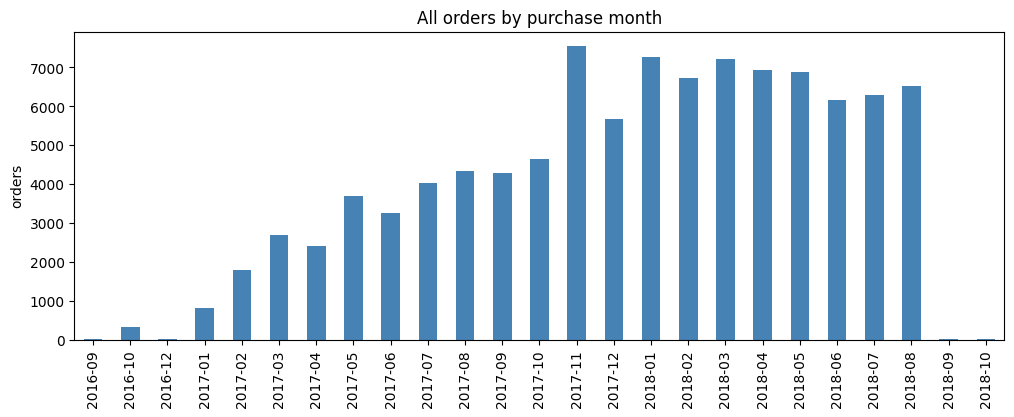

First and last months:


purchase_month,2016-09,2016-10,2016-12,2017-01,2018-08,2018-09,2018-10
orders,4,324,1,800,6512,16,4


In [14]:
orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M')
orders_by_month = orders['purchase_month'].value_counts().sort_index()

ax = orders_by_month.plot(kind='bar', color='steelblue', title='All orders by purchase month')
ax.set_xlabel('')
ax.set_ylabel('orders')
plt.show()

print("First and last months:")
display(pd.concat([orders_by_month.head(4), orders_by_month.tail(3)]).to_frame('orders').T)

In [15]:
# Status of orders in the last months
last_months = orders[orders['order_purchase_timestamp'] >= '2018-08-01']
pd.crosstab(last_months['purchase_month'], last_months['order_status'])

order_status,canceled,delivered,invoiced,shipped,unavailable
purchase_month,,,,,
2018-08,84,6351,23,47,7
2018-09,15,0,0,1,0
2018-10,4,0,0,0,0


**Findings:** 2016 was Olist's launch (4, 324 and 1 orders; none in November). The data effectively ends in August 2018: the few September–October 2018 records are almost all cancellations left over from the data extraction. **Reliable window: January 2017 – August 2018 (20 months).** Monthly charts and forecasting use only this period, and because 20 monthly points are too few, the sales forecast will use daily or weekly data.

In [16]:
# Analysis base from here on: delivered orders, reliable window, no batch-updated records
in_window = ((orders['purchase_month'] >= pd.Period('2017-01', 'M'))
             & (orders['purchase_month'] <= pd.Period('2018-08', 'M')))

analysis = orders[(orders['order_status'] == 'delivered') & in_window
                  & ~orders['flag_batch_delivery']].copy()
print(f"Orders in the analysis base: {len(analysis):,}")

Orders in the analysis base: 96,154


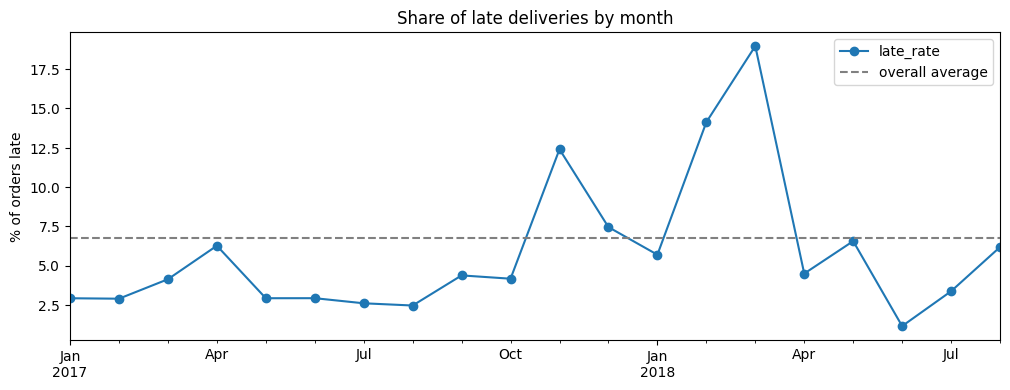

In [17]:
monthly = analysis.groupby('purchase_month').agg(orders=('order_id', 'count'),
                                                 late_rate=('was_late', 'mean'))

ax = (monthly['late_rate'] * 100).plot(marker='o', title='Share of late deliveries by month')
ax.axhline(analysis['was_late'].mean() * 100, linestyle='--', color='grey', label='overall average')
ax.set_ylabel('% of orders late')
ax.set_xlabel('')
ax.legend()
plt.show()

**Findings:** the late rate is usually 2.5–6%, with two spikes: **November 2017 (12.4%)**, right after the Black Friday surge, and **February–March 2018 (14.1% and 19.0%)**, when order volume was no higher than in January (5.7% late). Volume alone does not explain the second spike; section 12 shows where it hit.

## 8. Reviews: do late deliveries cause bad reviews?

In [18]:
reviews = raw['reviews'].copy()
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

print(f"Review rows:       {len(reviews):,}")
print(f"Unique review IDs: {reviews['review_id'].nunique():,}")
print(f"Unique order IDs:  {reviews['order_id'].nunique():,}")
print(f"Without a comment: {reviews['review_comment_message'].isna().mean():.0%}")

# Some orders were reviewed twice: keep the latest (the customer's final opinion)
reviews_latest = (reviews.sort_values('review_answer_timestamp')
                         .drop_duplicates('order_id', keep='last'))

(reviews_latest['review_score'].value_counts(normalize=True).sort_index() * 100).round(1).to_frame('% of reviews').T

Review rows:       99,224
Unique review IDs: 98,410
Unique order IDs:  98,673
Without a comment: 59%


review_score,1,2,3,4,5
% of reviews,11.5,3.2,8.2,19.3,57.8


In [19]:
analysis = analysis.merge(reviews_latest[['order_id', 'review_score']], on='order_id', how='left')
analysis['got_bad_review'] = ((analysis['review_score'] <= 2).astype(float)
                              .where(analysis['review_score'].notna()))   # 1 = 1–2 stars

late_vs_reviews = analysis.groupby('was_late').agg(orders=('order_id', 'count'),
                                                   average_score=('review_score', 'mean'),
                                                   bad_review_rate=('got_bad_review', 'mean'))
late_vs_reviews.index = ['on time', 'late']
late_vs_reviews.round(3)

,orders,average_score,bad_review_rate
on time,89665,4.291,0.092
late,6481,2.265,0.626


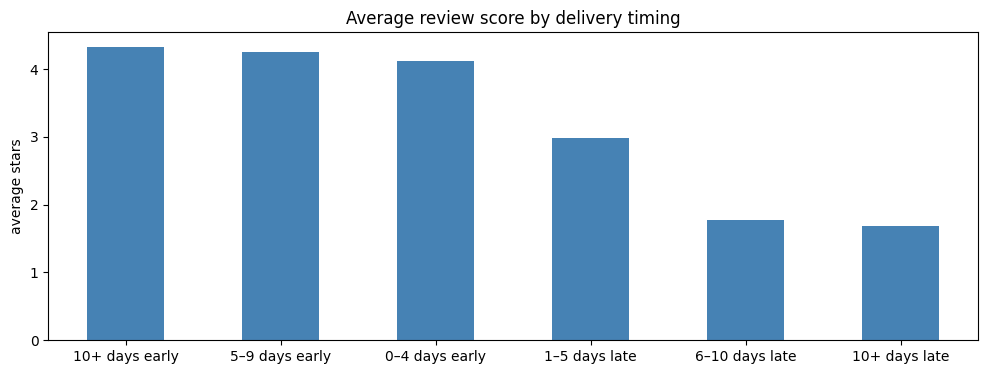

delay_group,10+ days early,5–9 days early,0–4 days early,1–5 days late,6–10 days late,10+ days late
mean,4.32,4.26,4.12,2.99,1.77,1.68
count,61269.00,20023.00,7883.00,2718.00,1629.00,1983.00


In [20]:
# Does it get worse the later the order arrives?
delay_bins = [-200, -10, -5, 0, 5, 10, 300]
delay_labels = ['10+ days early', '5–9 days early', '0–4 days early',
                '1–5 days late', '6–10 days late', '10+ days late']
analysis['delay_group'] = pd.cut(analysis['days_late'], bins=delay_bins, labels=delay_labels)

score_by_delay = analysis.groupby('delay_group', observed=True)['review_score'].agg(['mean', 'count'])
ax = score_by_delay['mean'].plot(kind='bar', color='steelblue', title='Average review score by delivery timing')
ax.set_ylabel('average stars')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.show()
score_by_delay.round(2).T

In [21]:
# Who writes comments?
has_comment = reviews_latest['review_comment_message'].notna()
(has_comment.groupby(reviews_latest['review_score']).mean() * 100).round(1).to_frame('% with a comment').T

review_score,1,2,3,4,5
% with a comment,76.6,68.1,43.5,31.2,35.9


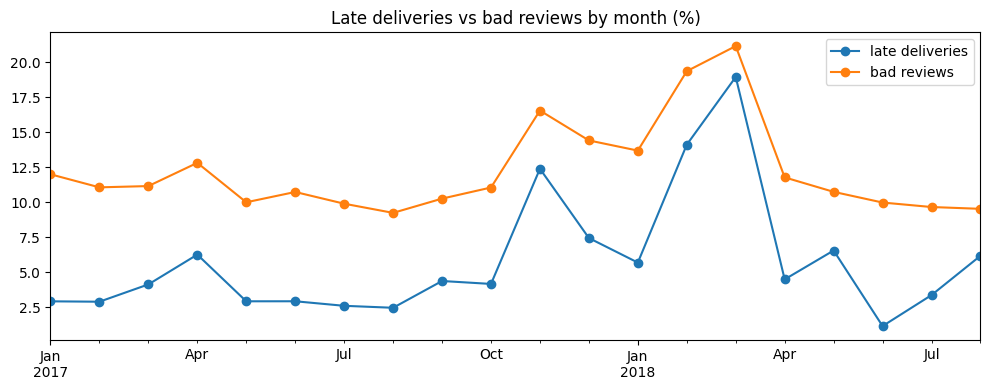

Correlation of the monthly rates: 0.94


In [22]:
# Month by month: do bad reviews follow late deliveries?
monthly_rates = analysis.groupby('purchase_month')[['was_late', 'got_bad_review']].mean() * 100

ax = monthly_rates.plot(marker='o', title='Late deliveries vs bad reviews by month (%)')
ax.legend(['late deliveries', 'bad reviews'])
ax.set_xlabel('')
plt.show()
print(f"Correlation of the monthly rates: {monthly_rates['was_late'].corr(monthly_rates['got_bad_review']):.2f}")

**Findings:**
- Some orders were reviewed twice, so only the latest review per order is kept; otherwise those orders would be counted twice.
- Scores are polarised: 58% five stars, 11.5% one star, few in between.
- **Late orders get a bad review (1–2 stars) 63% of the time vs 9% for on-time orders**, and the score falls step by step the later an order arrives: 4.3 stars when 10+ days early, 1.7 when 10+ days late.
- Month by month, bad reviews track late deliveries closely (**correlation 0.94**).
- Comments are mostly complaints: 77% of 1-star reviews include one vs 36% of 5-star reviews. They are ideal for finding problems but do not represent the average customer.
- Late orders are only 7% of orders, so **about two-thirds of bad reviews come from on-time orders**. Section 10 looks for the other causes.

## 9. Order items and products

In [23]:
items = raw['order_items']
items_per_order = items.groupby('order_id').size()

print(f"Item rows: {len(items):,} across {items['order_id'].nunique():,} orders")
print(f"Orders with one item: {(items_per_order == 1).mean():.1%}")
items[['price', 'freight_value']].describe().round(2).T

Item rows: 112,650 across 98,666 orders
Orders with one item: 90.1%


,count,mean,std,min,25%,50%,75%,max
price,112650.0,120.65,183.63,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.99,15.81,0.00,13.08,16.26,21.15,409.68


In [24]:
products = raw['products'].merge(raw['category_translation'], on='product_category_name', how='left')

# Two categories are missing from the translation table
manual_translations = {'pc_gamer': 'pc_gamer',
                       'portateis_cozinha_e_preparadores_de_alimentos': 'small_kitchen_appliances'}

products['flag_missing_details'] = products['product_category_name'].isna()
products['category'] = (products['product_category_name_english']
                        .fillna(products['product_category_name'].map(manual_translations))
                        .fillna('unknown'))

print("Missing values in products:")
display(products.isnull().sum()[lambda counts: counts > 0].to_frame('missing'))
print(f"Products still without a category: {products['category'].isna().sum()}")

Missing values in products:


,missing
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2
product_category_name_english,623


Products still without a category: 0


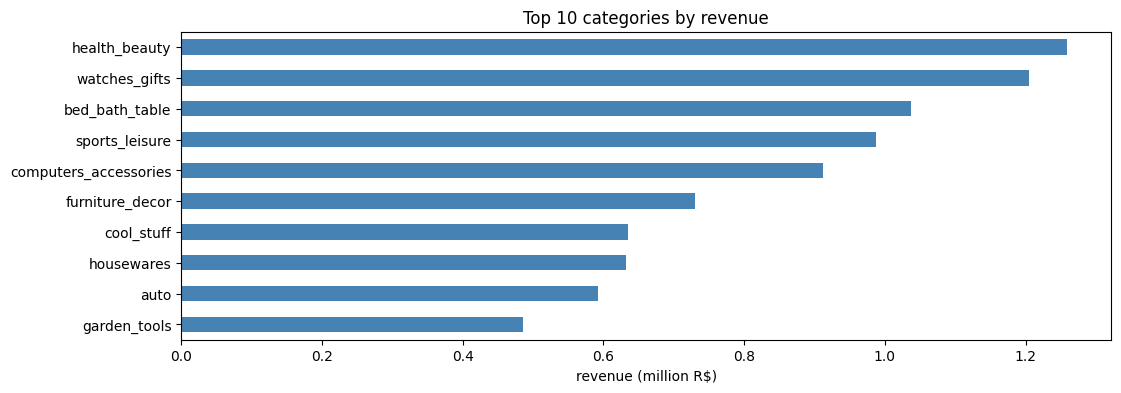

In [25]:
items_with_category = items.merge(products[['product_id', 'category', 'flag_missing_details']],
                                  on='product_id', how='left')

revenue_by_category = (items_with_category.groupby('category')['price'].sum()
                       .sort_values().tail(10) / 1e6)
ax = revenue_by_category.plot(kind='barh', color='steelblue', title='Top 10 categories by revenue')
ax.set_xlabel('revenue (million R$)')
ax.set_ylabel('')
plt.show()

**Findings:** 90% of orders contain a single item. Prices are heavily skewed (median R$75, mean R$121, maximum R$6,735), so price will be log-transformed for modelling. 610 products have no category or description details; they are kept as "unknown" and flagged, because their orders are real. Two categories were missing from the translation table and were translated by hand. Health & beauty, watches & gifts and bed & bath bring in the most revenue.

## 10. Other causes of bad reviews

About two-thirds of bad reviews come from orders that arrived **on time**, so lateness is not the whole story. Below, only on-time orders are compared, so lateness cannot explain any difference found.

In [26]:
# One row per order summarising its items
order_summary = items_with_category.groupby('order_id').agg(
    number_of_items=('order_item_id', 'count'),
    number_of_sellers=('seller_id', 'nunique'),
    items_price=('price', 'sum'),
    shipping_cost=('freight_value', 'sum'),
    product_category=('category', 'first'),
    has_incomplete_listing=('flag_missing_details', 'any'),
    first_seller_id=('seller_id', 'first'),
)
order_summary['shipping_share_of_total'] = (order_summary['shipping_cost']
                                            / (order_summary['items_price'] + order_summary['shipping_cost']))

analysis = analysis.merge(order_summary, left_on='order_id', right_index=True, how='left')
on_time = analysis[analysis['was_late'] == 0].copy()
print(f"On-time orders compared: {len(on_time):,}")

On-time orders compared: 89,665


In [27]:
# Split orders: is it the number of items or the number of sellers?
on_time['order_type'] = np.select(
    [on_time['number_of_items'] == 1, on_time['number_of_sellers'] == 1],
    ['1 item', 'several items, 1 seller'],
    default='several sellers')

(on_time.groupby('order_type')
        .agg(orders=('order_id', 'count'), bad_review_rate=('got_bad_review', 'mean'))
        .round(3))

,orders,bad_review_rate
order_type,,
1 item,80569,0.075
"several items, 1 seller",7837,0.210
several sellers,1259,0.469


In [28]:
# Shipping cost as a share of the total paid, in four equal groups
on_time['shipping_share_group'] = pd.qcut(on_time['shipping_share_of_total'], 4,
                                          labels=['lowest 25%', 'low-mid', 'mid-high', 'highest 25%'])
(on_time.groupby('shipping_share_group', observed=True)['got_bad_review'].mean() * 100).round(1).to_frame('% bad reviews').T

shipping_share_group,lowest 25%,low-mid,mid-high,highest 25%
% bad reviews,8.8,9.0,9.5,9.8


In [29]:
# Categories with at least 500 on-time orders
category_reviews = on_time.groupby('product_category').agg(orders=('order_id', 'count'),
                                                           bad_review_rate=('got_bad_review', 'mean'))
category_reviews = category_reviews[category_reviews['orders'] >= 500].sort_values('bad_review_rate')
pd.concat([category_reviews.tail(5)[::-1], category_reviews.head(5)],
          keys=['worst 5', 'best 5']).round(3)

orders  bad_review_rate
        product_category                                 
worst 5 office_furniture            1139            0.181
        unknown                     1260            0.128
        bed_bath_table              8473            0.118
        furniture_decor             5720            0.114
        computers_accessories       6072            0.113
best 5  luggage_accessories          965            0.055
        stationery                  2099            0.061
        musical_instruments          561            0.065
        fashion_bags_accessories    1701            0.070
        health_beauty               7923            0.073

**Findings (on-time orders only):**
- **Orders split across sellers are the second biggest cause of bad reviews:** 47% get a bad review vs 7.5% of single-item orders. Items from different sellers arrive separately, so customers often review before everything has arrived. They are only 1.4% of orders, but very risky.
- Several items from **one** seller still reach 21%, so multi-item orders are risky even without multiple sellers.
- **Shipping cost barely matters:** 8.7% to 9.8% across the four groups.
- **Product type matters moderately:** office furniture 18% vs luggage 5.5%; incomplete listings ("unknown") 12.8%.

Number of items and sellers, category and incomplete listing become features for the bad-review model.

## 11. Payments

In [30]:
payments = raw['payments']
print(f"Payment rows: {len(payments):,} for {payments['order_id'].nunique():,} orders")

display((payments['payment_type'].value_counts(normalize=True) * 100).round(1).to_frame('% of payments').T)
print(f"Paid in a single installment: {(payments['payment_installments'] == 1).mean():.1%}")
print(f"Payments of R$0: {(payments['payment_value'] == 0).sum()} | "
      f"0 installments: {(payments['payment_installments'] == 0).sum()} | "
      f"type 'not_defined': {(payments['payment_type'] == 'not_defined').sum()}")

Payment rows: 103,886 for 99,440 orders


payment_type,credit_card,boleto,voucher,debit_card,not_defined
% of payments,73.9,19.0,5.6,1.5,0.0


Paid in a single installment: 50.6%
Payments of R$0: 9 | 0 installments: 2 | type 'not_defined': 3


In [31]:
payments_per_order = payments.groupby('order_id').agg(
    total_paid=('payment_value', 'sum'),
    payment_installments=('payment_installments', 'max'),
    payment_type=('payment_type', 'first'),
)

# Does the amount paid equal item prices + shipping?
paid_vs_items = order_summary.join(payments_per_order, how='inner')
difference = paid_vs_items['total_paid'] - (paid_vs_items['items_price'] + paid_vs_items['shipping_cost'])
print(f"Orders compared: {len(paid_vs_items):,}")
print(f"Paid within R$1 of price + shipping: {(difference.abs() <= 1).mean():.1%}")
print(f"Orders with a payment but no items: {len(set(payments_per_order.index) - set(order_summary.index))}")

Orders compared: 98,665
Paid within R$1 of price + shipping: 99.7%
Orders with a payment but no items: 775


In [32]:
on_time = on_time.merge(payments_per_order[['payment_type']], left_on='order_id', right_index=True, how='left')
(on_time.groupby('payment_type')['got_bad_review'].mean() * 100).round(1).to_frame('% bad reviews (on time)').T

payment_type,boleto,credit_card,debit_card,voucher
% bad reviews (on time),9.2,9.2,8.5,10.4


**Findings:** credit card dominates (74%), followed by boleto, a Brazilian bank slip (19%). Half of payments are split into installments. **99.7% of orders were paid exactly price + shipping**, so revenue figures can be trusted. The 775 orders with a payment but no items never went ahead. Payment type does not affect satisfaction (8.5–10.4% bad reviews), so it is not used in the bad-review model.

## 12. Geography: states, distance and the Feb–Mar 2018 crisis

In [33]:
sellers = raw['sellers']
people = customers.drop_duplicates('customer_unique_id')

pd.DataFrame({
    '% of customers': people['customer_state'].value_counts(normalize=True).head(6) * 100,
    '% of sellers': sellers['seller_state'].value_counts(normalize=True).head(6) * 100,
}).round(1).T

,MG,PR,RJ,RS,SC,SP
% of customers,11.7,5.1,12.9,5.5,3.7,41.9
% of sellers,7.9,11.3,5.5,4.2,6.1,59.7


In [34]:
analysis = analysis.merge(customers[['customer_id', 'customer_unique_id', 'customer_state', 'customer_zip_code_prefix']],
                          on='customer_id', how='left')

by_state = analysis.groupby('customer_state').agg(orders=('order_id', 'count'),
                                                  median_days=('days_to_deliver', 'median'),
                                                  late_rate=('was_late', 'mean'),
                                                  bad_review_rate=('got_bad_review', 'mean'))
by_state = by_state[by_state['orders'] >= 500].sort_values('late_rate', ascending=False)
by_state.round(3)

,orders,median_days,late_rate,bad_review_rate
customer_state,,,,
MA,712,19.0,0.176,0.201
CE,1272,18.0,0.138,0.171
RJ,12310,12.0,0.121,0.183
BA,3246,16.0,0.120,0.170
PA,941,21.0,0.112,0.179
ES,1989,13.0,0.107,0.138
PB,515,18.0,0.105,0.149
MS,701,13.0,0.097,0.133
PE,1583,15.0,0.094,0.146


In [35]:
# Which states were hit hardest in Feb–Mar 2018?
crisis_months = [pd.Period('2018-02', 'M'), pd.Period('2018-03', 'M')]
analysis['period'] = np.where(analysis['purchase_month'].isin(crisis_months), 'Feb–Mar 2018', 'other months')

crisis = (analysis.groupby(['customer_state', 'period'])['was_late'].mean().unstack() * 100).round(1)
crisis['increase'] = crisis['Feb–Mar 2018'] - crisis['other months']
crisis.loc[by_state.index].sort_values('increase', ascending=False).head(6)

period,Feb–Mar 2018,other months,increase
customer_state,,,
CE,45.2,8.7,36.5
MA,41.3,13.5,27.8
RJ,34.3,8.5,25.8
PA,33.1,7.8,25.3
MS,29.8,5.5,24.3
ES,25.9,8.1,17.8


In [36]:
# Straight-line distance from the (first) seller to the customer
zip_location = raw['geolocation'].groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()

analysis = analysis.merge(sellers[['seller_id', 'seller_zip_code_prefix']],
                          left_on='first_seller_id', right_on='seller_id', how='left')
analysis = analysis.merge(zip_location.add_prefix('customer_'), left_on='customer_zip_code_prefix',
                          right_index=True, how='left')
analysis = analysis.merge(zip_location.add_prefix('seller_'), left_on='seller_zip_code_prefix',
                          right_index=True, how='left')

def distance_km(lat1, lon1, lat2, lon2):
    """Haversine distance between two points on Earth, in km."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

analysis['distance_seller_to_customer_km'] = distance_km(
    analysis['customer_geolocation_lat'], analysis['customer_geolocation_lng'],
    analysis['seller_geolocation_lat'], analysis['seller_geolocation_lng'])

print(f"Orders with a distance: {analysis['distance_seller_to_customer_km'].notna().sum():,} of {len(analysis):,}")
print(f"Distances over 4,500 km (longer than Brazil): {(analysis['distance_seller_to_customer_km'] > 4500).sum()}")

Orders with a distance: 95,676 of 96,154
Distances over 4,500 km (longer than Brazil): 4


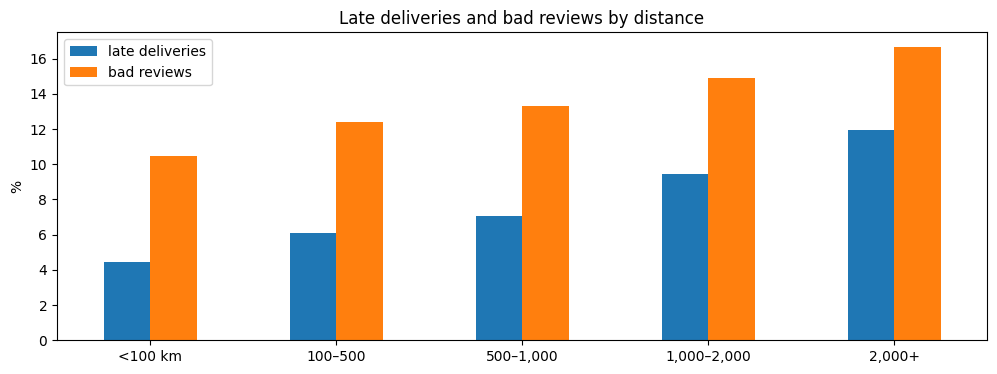

,orders,median_days,late_rate,bad_review_rate
distance_seller_to_customer_km,,,,
<100 km,17836,5.0,0.044,0.105
100–500,36875,9.0,0.061,0.124
"500–1,000",25663,12.0,0.071,0.133
"1,000–2,000",9704,15.0,0.094,0.149
"2,000+",5571,18.0,0.119,0.167


In [37]:
distance_groups = pd.cut(analysis['distance_seller_to_customer_km'], bins=[0, 100, 500, 1000, 2000, 4500],
                         labels=['<100 km', '100–500', '500–1,000', '1,000–2,000', '2,000+'])
by_distance = analysis.groupby(distance_groups, observed=True).agg(orders=('order_id', 'count'),
                                                                   median_days=('days_to_deliver', 'median'),
                                                                   late_rate=('was_late', 'mean'),
                                                                   bad_review_rate=('got_bad_review', 'mean'))

ax = (by_distance[['late_rate', 'bad_review_rate']] * 100).plot(kind='bar', title='Late deliveries and bad reviews by distance')
ax.set_ylabel('%')
ax.set_xlabel('')
ax.legend(['late deliveries', 'bad reviews'])
plt.xticks(rotation=0)
plt.show()
by_distance.round(3)

**Findings:**
- 42% of customers and 60% of sellers are in São Paulo (SP), so most parcels travel outward from SP.
- **Distance drives delivery performance:** under 100 km, orders take 5 days (4.4% late, 10.5% bad reviews); over 2,000 km, 18 days (11.9% late, 16.7% bad reviews). Every step further is worse.
- Far states do worst (MA 17.6% late, CE 13.8%); SP, MG and PR do best (4–4.5%).
- **Rio de Janeiro underperforms for its location:** close to SP, yet 12.1% late and 18.3% bad reviews across 12,000+ orders, which points to local delivery problems.
- **The Feb–Mar 2018 crisis hit long-distance routes:** Ceará went from 8.7% to 45.2% late, while SP, MG and PR are not among the biggest increases.
- Four distances over 4,500 km (longer than Brazil) come from wrong coordinates; they are replaced with the state median when the master table is built.

## 13. Building the master table

One row per delivered order (January 2017 – August 2018, batch-updated records removed), with every feature built above and clear column names.

In [38]:
master = analysis.copy()

# Delivery stages
master['days_seller_to_ship'] = (master['order_delivered_carrier_date'] - master['order_approved_at']).dt.days
master['days_in_transit'] = (master['order_delivered_customer_date'] - master['order_delivered_carrier_date']).dt.days
master['is_peak_period'] = master['purchase_month'].isin(
    [pd.Period('2017-11', 'M'), pd.Period('2018-02', 'M'), pd.Period('2018-03', 'M')])

# Fix 1: carrier date a few hours before approval shows as -1 day (rounding) -> same day
master.loc[master['days_seller_to_ship'] == -1, 'days_seller_to_ship'] = 0
# Fix 2: carrier date days before approval is impossible -> flag and empty
master['flag_bad_ship_date'] = master['days_seller_to_ship'] < -1
master.loc[master['flag_bad_ship_date'], 'days_seller_to_ship'] = np.nan

# Fix 3: impossible distances (wrong coordinates) and missing ones -> median distance of the state
master.loc[master['distance_seller_to_customer_km'] > 4500, 'distance_seller_to_customer_km'] = np.nan
state_median_distance = master.groupby('customer_state')['distance_seller_to_customer_km'].transform('median')
master['distance_seller_to_customer_km'] = master['distance_seller_to_customer_km'].fillna(state_median_distance)

# Payments (0 installments -> 1)
master = master.merge(payments_per_order[['payment_installments', 'payment_type']],
                      left_on='order_id', right_index=True, how='left')
master['payment_installments'] = master['payment_installments'].clip(lower=1)

master = master.rename(columns={'customer_unique_id': 'customer_person_id',
                                'order_purchase_timestamp': 'purchase_date'})

master_columns = [
    'order_id', 'customer_person_id', 'purchase_date', 'purchase_month', 'customer_state',
    'distance_seller_to_customer_km', 'days_promised', 'days_to_deliver', 'days_seller_to_ship',
    'days_in_transit', 'days_late', 'was_late', 'is_peak_period', 'number_of_items',
    'number_of_sellers', 'items_price', 'shipping_cost', 'shipping_share_of_total', 'product_category',
    'has_incomplete_listing', 'payment_installments', 'payment_type', 'review_score',
    'got_bad_review', 'flag_bad_ship_date',
]
master = master[master_columns]

In [39]:
# Quality checks
assert master['order_id'].is_unique, 'duplicate orders'
assert (master['days_seller_to_ship'].dropna() >= 0).all()
assert (master['payment_installments'] >= 1).all()
assert master['distance_seller_to_customer_km'].max() <= 4500

print(f"Rows: {len(master):,} | Columns: {master.shape[1]} | Real customers: {master['customer_person_id'].nunique():,}")
print(f"Purchase dates: {master['purchase_date'].min():%d %b %Y} to {master['purchase_date'].max():%d %b %Y}")
print(f"Seller shipping dates emptied (impossible): {master['flag_bad_ship_date'].sum()}")
print("\nRemaining missing values (all expected):")
display(master.isnull().sum()[lambda counts: counts > 0].to_frame('missing'))
master.head(3)

Rows: 96,154 | Columns: 25 | Real customers: 93,053
Purchase dates: 05 Jan 2017 to 29 Aug 2018
Seller shipping dates emptied (impossible): 453

Remaining missing values (all expected):


,missing
days_to_deliver,8
days_seller_to_ship,474
days_in_transit,28
days_late,8
was_late,8
review_score,641
got_bad_review,641


,order_id,customer_person_id,purchase_date,purchase_month,customer_state,distance_seller_to_customer_km,days_promised,days_to_deliver,days_seller_to_ship,days_in_transit,days_late,was_late,is_peak_period,number_of_items,number_of_sellers,items_price,shipping_cost,shipping_share_of_total,product_category,has_incomplete_listing,payment_installments,payment_type,review_score,got_bad_review,flag_bad_ship_date
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-10,SP,18.576110,15,8.0,2.0,6.0,-8.0,0.0,False,1,1,29.99,8.72,0.225265,housewares,False,1,credit_card,4.0,0.0,False
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-07,BA,851.495069,19,13.0,0.0,12.0,-6.0,0.0,False,1,1,118.70,22.76,0.160894,perfumery,False,1,boleto,4.0,0.0,False
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08,GO,514.410666,26,9.0,0.0,9.0,-18.0,0.0,False,1,1,159.90,19.22,0.107302,auto,False,3,credit_card,5.0,0.0,False


In [40]:
master.to_csv(DATA_PATH + 'master_orders.csv', index=False)
print('Saved master_orders.csv')

Saved master_orders.csv


**Result:** `master_orders.csv`, with 96,154 delivered orders × 25 columns, 93,053 real customers, January 2017 – August 2018. Fixes applied while building it: seller shipping days of −1 (a few hours' rounding) set to 0; 453 impossible values emptied and flagged; 0 payment installments set to 1; impossible and missing distances replaced with the state median. The remaining gaps are expected: 8 orders without a delivery date, 641 without a review, and seller or transit days where a date was emptied.

## 14. Cleaning decisions and key insights

### Cleaning decisions

| Problem | Rows | Decision |
| --- | --- | --- |
| Missing dates for orders not delivered yet | ~2,950 | Kept empty (structural) |
| Delivered orders without an approval date | 14 | Purchase time + median delay (20 min), flagged |
| Delivered orders without a delivery date | 8 | Kept empty; excluded from delivery statistics |
| Delivered to customer before carrier pickup | 23 | Carrier date emptied, flagged |
| Batch-updated deliveries (19 Sep 2017) | 57 | Flagged and excluded |
| Delivered orders outside Jan 2017 – Aug 2018 | 267 | Excluded |
| Orders reviewed more than once | 551 extra reviews | Latest review kept |
| Products without category or details | 610 | Category "unknown", flagged |
| Categories missing from the translation table | 2 | Translated by hand |
| Seller shipping days of −1 / below −1 | rounding / 453 | Set to 0 / emptied and flagged |
| Payments with 0 installments | 2 | Set to 1 |
| Distances over 4,500 km | 4 | Replaced with state median |

### Key insights

1. **Late deliveries are the biggest driver of bad reviews:** 63% of late orders get 1–2 stars vs 9% of on-time orders; monthly correlation 0.94.
2. **Orders split across sellers are the second:** 47% bad reviews even when delivered on time.
3. **Distance from São Paulo drives delays**, and Rio de Janeiro underperforms for its location.
4. **Delivery promises are padded:** 23 days promised vs 10 delivered.
5. **Peaks strain logistics:** Black Friday 2017, and a Feb–Mar 2018 crisis on long-distance routes (Ceará reached 45% late).
6. **Shipping cost and payment method barely affect satisfaction.**
7. **Only 3.1% of customers order more than once** (analysed in notebook 02).

### Recommendations

- Ship multi-seller orders together, or tell customers clearly that items will arrive separately.
- Recruit sellers or add warehouses outside São Paulo, and set realistic promised dates for far states.
- Investigate last-mile delivery in Rio de Janeiro.
- Add carrier capacity before known peaks such as Black Friday.

**Next:** notebook 02 analyses repeat customers and cohort retention, and prepares feature transforms.